In [3]:
import pandas as pd
import numpy as np

In [4]:
df = pd.read_csv("MLProject2026/data/case1/train1.csv")
df["kilo_rpm"] = df["speed_rpm"] / 1000
df["delta_p"] = df["outlet_pressure_bar"] - df["inlet_pressure_bar"]
dataset = df[["power_w", "kilo_rpm", "delta_p", "flow_m3_h"]].copy()

Training MSE: 15.995
Test MSE: 28.667


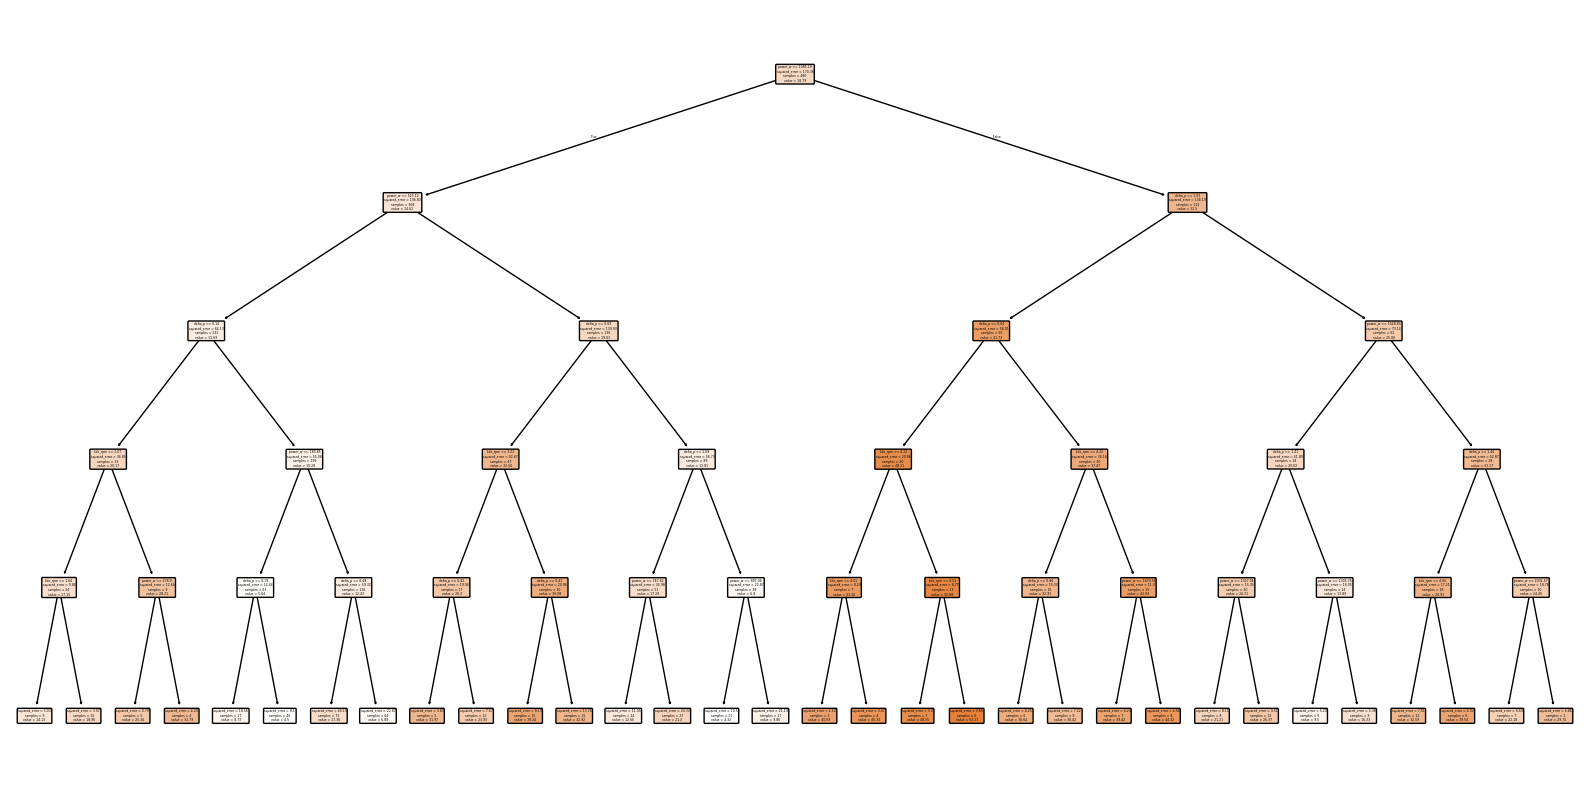

In [6]:
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

target = "flow_m3_h"
feature_names = [column for column in dataset.columns if column != target]
X_train = dataset[feature_names]
y_train = dataset[target]

test_df = pd.read_csv("MLProject2026/data/case1/test1.csv")
test_df["kilo_rpm"] = test_df["speed_rpm"] / 1000
test_df["delta_p"] = test_df["outlet_pressure_bar"] - test_df["inlet_pressure_bar"]
test_dataset = test_df[feature_names + [target]]
X_test = test_dataset[feature_names]
y_test = test_dataset[target]

model = DecisionTreeRegressor(max_depth=5, criterion="squared_error", random_state=0)
model.fit(X_train, y_train)

train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)
print(f"Training MSE: {mean_squared_error(y_train, train_predictions):.3f}")
print(f"Test MSE: {mean_squared_error(y_test, test_predictions):.3f}")

plt.figure(figsize=(16, 8))
plot_tree(
    model,
    feature_names=feature_names,
    filled=True,
    rounded=True,
    precision=2,
)
plt.tight_layout()
plt.show()

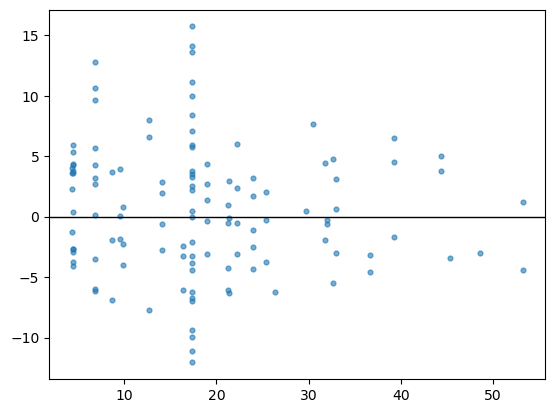

In [7]:
res = y_test-test_predictions
plt.scatter(test_predictions, res, s=12, alpha=0.6)
plt.axhline(0, color="k", lw=1)
plt.xlabel("")
plt.ylabel("")
plt.title("")
plt.show()